In [2]:
import os

folder = r"C:\Users\aarus\Downloads\Big Data Dataset"

for file in os.listdir(folder):
    if file.endswith(".parquet"):
        size_mb = os.path.getsize(
            os.path.join(folder, file)
        ) / (1024 * 1024)
        print(file, round(size_mb, 2), "MB")

fhvhv_tripdata_2024-01.parquet 450.86 MB
fhvhv_tripdata_2024-02.parquet 441.05 MB
fhvhv_tripdata_2024-03.parquet 484.41 MB


In [3]:
import pyspark
print("PySpark version:", pyspark.__version__)

PySpark version: 4.2.0


In [4]:
import os
import sys
from pyspark.sql import SparkSession

# Keep Spark Python workers on the same Python interpreter as this notebook.
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"

spark = (
    SparkSession.builder
    .appName("SustainableUrbanMobilityAnalytics")
    .master("local[2]")
    .config("spark.pyspark.python", sys.executable)
    .config("spark.driver.host", "127.0.0.1")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .getOrCreate()
)

print("Spark session ready")
print("Python:", sys.executable)
print("Spark:", spark.version)


Spark session ready
Python: c:\Users\aarus\AppData\Local\Programs\Python\Python313\python.exe
Spark: 4.2.0


In [5]:
import os

folder = r"C:\Users\aarus\Downloads\Big Data Dataset"
jan_path = os.path.join(folder, "fhvhv_tripdata_2024-01.parquet")

df_jan = spark.read.parquet(jan_path)

print("January file loaded successfully!")
print("Columns:", len(df_jan.columns))

df_jan.printSchema()

January file loaded successfully!
Columns: 24
root
 |-- hvfhs_license_num: string (nullable = true)
 |-- dispatching_base_num: string (nullable = true)
 |-- originating_base_num: string (nullable = true)
 |-- request_datetime: timestamp_ntz (nullable = true)
 |-- on_scene_datetime: timestamp_ntz (nullable = true)
 |-- pickup_datetime: timestamp_ntz (nullable = true)
 |-- dropoff_datetime: timestamp_ntz (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- trip_miles: double (nullable = true)
 |-- trip_time: long (nullable = true)
 |-- base_passenger_fare: double (nullable = true)
 |-- tolls: double (nullable = true)
 |-- bcf: double (nullable = true)
 |-- sales_tax: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- airport_fee: double (nullable = true)
 |-- tips: double (nullable = true)
 |-- driver_pay: double (nullable = true)
 |-- shared_request_flag: string (nullable = true)
 |-- shared_match

In [6]:
from pyspark.sql import functions as F

df_jan.select(
    F.count("*").alias("total_records"),
    F.min("pickup_datetime").alias("first_pickup"),
    F.max("pickup_datetime").alias("last_pickup")
).show(truncate=False)

+-------------+-------------------+-------------------+
|total_records|first_pickup       |last_pickup        |
+-------------+-------------------+-------------------+
|19663930     |2024-01-01 00:00:00|2024-01-31 23:59:59|
+-------------+-------------------+-------------------+



In [7]:
feb_path = os.path.join(
    folder, "fhvhv_tripdata_2024-02.parquet"
)

df_feb = spark.read.parquet(feb_path)

print("February file loaded successfully!")
df_feb.printSchema()

February file loaded successfully!
root
 |-- hvfhs_license_num: string (nullable = true)
 |-- dispatching_base_num: string (nullable = true)
 |-- originating_base_num: string (nullable = true)
 |-- request_datetime: timestamp_ntz (nullable = true)
 |-- on_scene_datetime: timestamp_ntz (nullable = true)
 |-- pickup_datetime: timestamp_ntz (nullable = true)
 |-- dropoff_datetime: timestamp_ntz (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- trip_miles: double (nullable = true)
 |-- trip_time: long (nullable = true)
 |-- base_passenger_fare: double (nullable = true)
 |-- tolls: double (nullable = true)
 |-- bcf: double (nullable = true)
 |-- sales_tax: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- airport_fee: double (nullable = true)
 |-- tips: double (nullable = true)
 |-- driver_pay: double (nullable = true)
 |-- shared_request_flag: string (nullable = true)
 |-- shared_match_flag: stri

In [8]:
df_feb.select(
    F.count("*").alias("total_records"),
    F.min("pickup_datetime").alias("first_pickup"),
    F.max("pickup_datetime").alias("last_pickup")
).show(truncate=False)

+-------------+-------------------+-------------------+
|total_records|first_pickup       |last_pickup        |
+-------------+-------------------+-------------------+
|19359148     |2024-02-01 00:00:00|2024-02-29 23:59:59|
+-------------+-------------------+-------------------+



In [9]:
mar_path = os.path.join(
    folder, "fhvhv_tripdata_2024-03.parquet"
)

df_mar = spark.read.parquet(mar_path)

print("March file loaded successfully!")
df_mar.printSchema()

March file loaded successfully!
root
 |-- hvfhs_license_num: string (nullable = true)
 |-- dispatching_base_num: string (nullable = true)
 |-- originating_base_num: string (nullable = true)
 |-- request_datetime: timestamp_ntz (nullable = true)
 |-- on_scene_datetime: timestamp_ntz (nullable = true)
 |-- pickup_datetime: timestamp_ntz (nullable = true)
 |-- dropoff_datetime: timestamp_ntz (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- trip_miles: double (nullable = true)
 |-- trip_time: long (nullable = true)
 |-- base_passenger_fare: double (nullable = true)
 |-- tolls: double (nullable = true)
 |-- bcf: double (nullable = true)
 |-- sales_tax: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- airport_fee: double (nullable = true)
 |-- tips: double (nullable = true)
 |-- driver_pay: double (nullable = true)
 |-- shared_request_flag: string (nullable = true)
 |-- shared_match_flag: string 

In [10]:
df_mar.select(
    F.count("*").alias("total_records"),
    F.min("pickup_datetime").alias("first_pickup"),
    F.max("pickup_datetime").alias("last_pickup")
).show(truncate=False)

+-------------+-------------------+-------------------+
|total_records|first_pickup       |last_pickup        |
+-------------+-------------------+-------------------+
|21280788     |2024-03-01 00:00:00|2024-03-31 23:59:59|
+-------------+-------------------+-------------------+



In [11]:
from functools import reduce

df_all = reduce(
    lambda left, right: left.unionByName(right),
    [df_jan, df_feb, df_mar]
)

print("Combined DataFrame created successfully!")
print("Columns:", len(df_all.columns))

Combined DataFrame created successfully!
Columns: 24


In [12]:
from pyspark.sql import functions as F

df_all.select(
    F.count("*").alias("total_records"),
    F.countDistinct("pickup_datetime").alias("unique_pickup_timestamps"),
    F.min("pickup_datetime").alias("first_pickup"),
    F.max("pickup_datetime").alias("last_pickup")
).show(truncate=False)

+-------------+------------------------+-------------------+-------------------+
|total_records|unique_pickup_timestamps|first_pickup       |last_pickup        |
+-------------+------------------------+-------------------+-------------------+
|60303866     |7682310                 |2024-01-01 00:00:00|2024-03-31 23:59:59|
+-------------+------------------------+-------------------+-------------------+



In [13]:
from pyspark.sql import functions as F

important_cols = [
    "pickup_datetime",
    "dropoff_datetime",
    "PULocationID",
    "DOLocationID",
    "trip_miles",
    "trip_time",
    "base_passenger_fare",
    "driver_pay"
]

df_all.select([
    F.sum(
        F.when(F.col(c).isNull(), 1).otherwise(0)
    ).alias(c)
    for c in important_cols
]).show(truncate=False)

+---------------+----------------+------------+------------+----------+---------+-------------------+----------+
|pickup_datetime|dropoff_datetime|PULocationID|DOLocationID|trip_miles|trip_time|base_passenger_fare|driver_pay|
+---------------+----------------+------------+------------+----------+---------+-------------------+----------+
|0              |0               |0           |0           |0         |0        |0                  |0         |
+---------------+----------------+------------+------------+----------+---------+-------------------+----------+



In [14]:
from pyspark.sql import functions as F

df_all.groupBy(df_all.columns) \
    .count() \
    .filter(F.col("count") > 1) \
    .select(
        F.sum(F.col("count") - 1).alias("extra_duplicate_rows")
    ) \
    .show()

+--------------------+
|extra_duplicate_rows|
+--------------------+
|                NULL|
+--------------------+



In [15]:
duplicate_groups = (
    df_all.groupBy(df_all.columns)
    .count()
    .filter(F.col("count") > 1)
)

duplicate_groups.agg(
    F.coalesce(
        F.sum(F.col("count") - 1), F.lit(0)
    ).alias("extra_duplicate_rows")
).show()

+--------------------+
|extra_duplicate_rows|
+--------------------+
|                   0|
+--------------------+



In [16]:
df_hourly = (
    df_all
    .withColumn("pickup_date", F.to_date("pickup_datetime"))
    .withColumn("pickup_hour", F.hour("pickup_datetime"))
    .groupBy("pickup_date", "pickup_hour")
    .agg(F.count("*").alias("total_pickups"))
    .orderBy("pickup_date", "pickup_hour")
)

df_hourly.show(10, truncate=False)

+-----------+-----------+-------------+
|pickup_date|pickup_hour|total_pickups|
+-----------+-----------+-------------+
|2024-01-01 |0          |52634        |
|2024-01-01 |1          |59460        |
|2024-01-01 |2          |57227        |
|2024-01-01 |3          |49172        |
|2024-01-01 |4          |34025        |
|2024-01-01 |5          |21712        |
|2024-01-01 |6          |17137        |
|2024-01-01 |7          |15650        |
|2024-01-01 |8          |13725        |
|2024-01-01 |9          |13740        |
+-----------+-----------+-------------+
only showing top 10 rows


In [17]:
print("hourly_pd exists:", "hourly_pd" in globals())
print("hourly_pd-like variables:",
      [v for v in globals() if "hourly" in v.lower()])

hourly_pd exists: False
hourly_pd-like variables: ['df_hourly']


In [18]:
print(df_hourly.head())
print(df_hourly.columns)

Row(pickup_date=datetime.date(2024, 1, 1), pickup_hour=0, total_pickups=52634)
['pickup_date', 'pickup_hour', 'total_pickups']


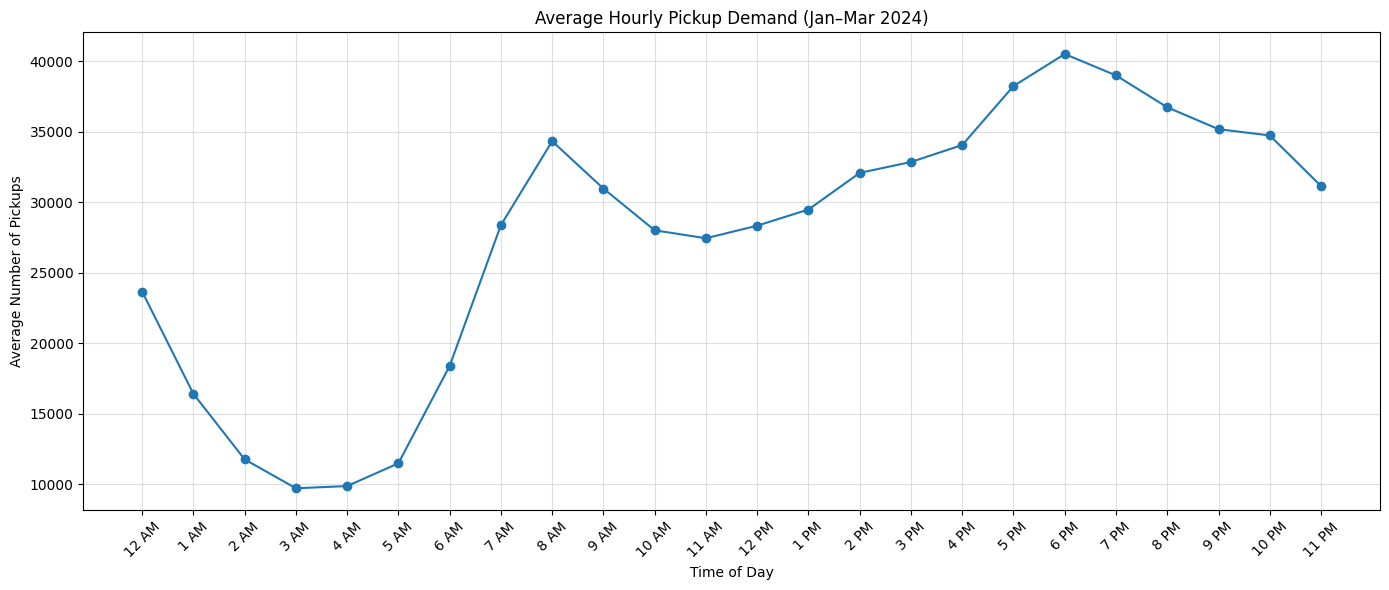

In [19]:
import matplotlib.pyplot as plt

# Convert existing Spark DataFrame to Pandas
hourly_pd = df_hourly.toPandas()

# Calculate average pickups for each hour across all days
hourly_pattern = (
    hourly_pd.groupby("pickup_hour")["total_pickups"]
    .mean()
    .reindex(range(24))
)

# Create time labels
time_labels = [
    f"{h % 12 or 12} {'AM' if h < 12 else 'PM'}"
    for h in range(24)
]

# Plot the graph
plt.figure(figsize=(14, 6))

plt.plot(
    range(24),
    hourly_pattern.values,
    marker="o"
)

plt.title("Average Hourly Pickup Demand (Jan–Mar 2024)")
plt.xlabel("Time of Day")
plt.ylabel("Average Number of Pickups")
plt.xticks(range(24), time_labels, rotation=45)
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

In [20]:
peak_hour = hourly_pattern.idxmax()
peak_demand = hourly_pattern.max()

lowest_hour = hourly_pattern.idxmin()
lowest_demand = hourly_pattern.min()

print("Peak hour:", peak_hour)
print("Peak average pickups:", round(peak_demand, 2))

print("Lowest hour:", lowest_hour)
print("Lowest average pickups:", round(lowest_demand, 2))

Peak hour: 18
Peak average pickups: 40507.81
Lowest hour: 3
Lowest average pickups: 9705.69


In [21]:
from pyspark.sql import functions as F

df_daily = (
    df_all
    .withColumn("pickup_date", F.to_date("pickup_datetime"))
    .withColumn(
        "day_type",
        F.when(F.dayofweek("pickup_datetime").isin(1, 7), "Weekend")
         .otherwise("Weekday")
    )
    .groupBy("pickup_date", "day_type")
    .agg(F.count("*").alias("total_pickups"))
)

df_day_type = (
    df_daily
    .groupBy("day_type")
    .agg(
        F.avg("total_pickups").alias("average_daily_pickups"),
        F.countDistinct("pickup_date").alias("number_of_days")
    )
)

df_day_type.show(truncate=False)

+--------+---------------------+--------------+
|day_type|average_daily_pickups|number_of_days|
+--------+---------------------+--------------+
|Weekday |635729.0615384616    |65            |
|Weekend |730056.8076923077    |26            |
+--------+---------------------+--------------+



In [22]:
import pandas as pd
import matplotlib.pyplot as plt

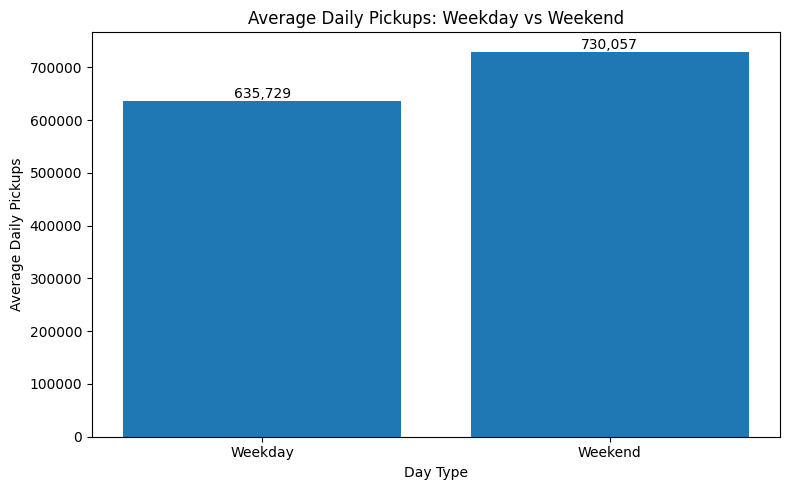

In [23]:
import pandas as pd
import matplotlib.pyplot as plt

day_pd = df_day_type.toPandas()

day_pd["day_type"] = pd.Categorical(
    day_pd["day_type"],
    categories=["Weekday", "Weekend"],
    ordered=True
)

day_pd = day_pd.sort_values("day_type")

plt.figure(figsize=(8, 5))
bars = plt.bar(
    day_pd["day_type"].astype(str),
    day_pd["average_daily_pickups"]
)

plt.title("Average Daily Pickups: Weekday vs Weekend")
plt.xlabel("Day Type")
plt.ylabel("Average Daily Pickups")

for bar in bars:
    value = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:,.0f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

Weekday average
635,729
65 days

Weekend average
730,057
26 days

Weekend demand approximately 14.8% higher hai.



In [24]:
from pyspark.sql import functions as F

df_monthly = (
    df_all
    .withColumn("pickup_month", F.date_format("pickup_datetime", "yyyy-MM"))
    .groupBy("pickup_month")
    .agg(
        F.count("*").alias("total_pickups"),
        F.countDistinct(F.to_date("pickup_datetime")).alias("number_of_days")
    )
    .orderBy("pickup_month")
)

df_monthly.show(truncate=False)

+------------+-------------+--------------+
|pickup_month|total_pickups|number_of_days|
+------------+-------------+--------------+
|2024-01     |19663930     |31            |
|2024-02     |19359148     |29            |
|2024-03     |21280788     |31            |
+------------+-------------+--------------+



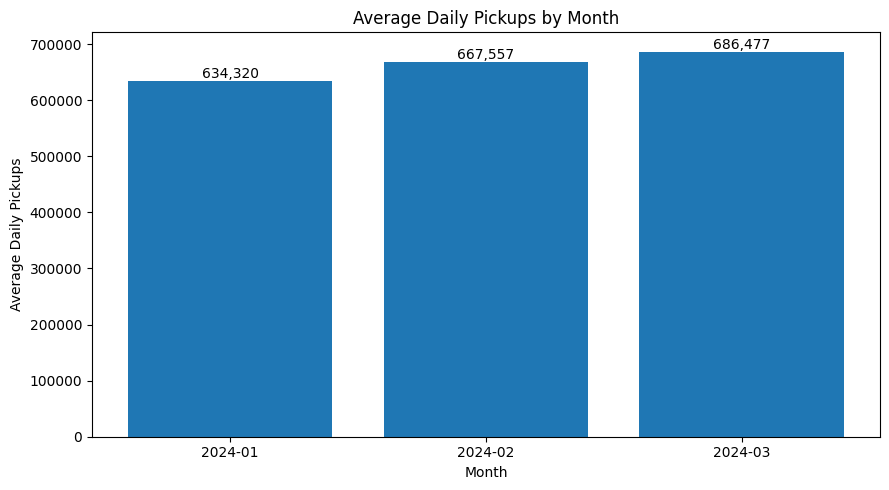

In [25]:
import matplotlib.pyplot as plt
import pandas as pd

monthly_pd = df_monthly.toPandas()

monthly_pd["average_daily_pickups"] = (
    monthly_pd["total_pickups"] / monthly_pd["number_of_days"]
)

plt.figure(figsize=(9, 5))

bars = plt.bar(
    monthly_pd["pickup_month"],
    monthly_pd["average_daily_pickups"]
)

plt.title("Average Daily Pickups by Month")
plt.xlabel("Month")
plt.ylabel("Average Daily Pickups")

for bar in bars:
    value = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:,.0f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [26]:
from pyspark.sql import functions as F

df_top_locations = (
    df_all
    .groupBy("PULocationID")
    .agg(
        F.count("*").alias("total_pickups")
    )
    .orderBy(F.desc("total_pickups"))
    .limit(10)
)

df_top_locations.show(truncate=False)

+------------+-------------+
|PULocationID|total_pickups|
+------------+-------------+
|138         |1069940      |
|132         |1059947      |
|79          |842994       |
|61          |807880       |
|230         |738735       |
|161         |716426       |
|231         |702472       |
|68          |666207       |
|234         |656569       |
|37          |653852       |
+------------+-------------+



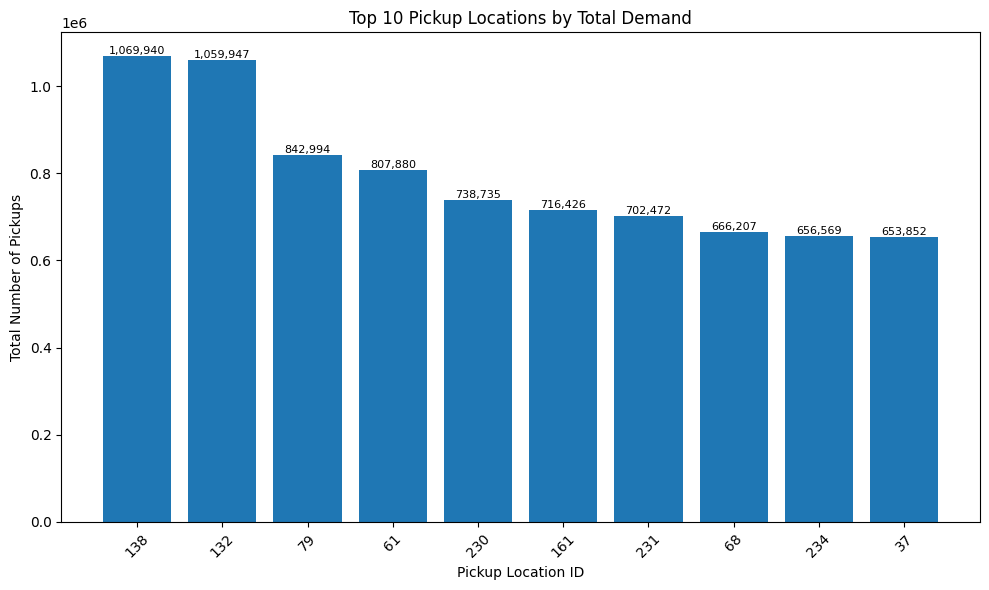

In [27]:
import matplotlib.pyplot as plt

locations_pd = df_top_locations.toPandas()

plt.figure(figsize=(10, 6))

bars = plt.bar(
    locations_pd["PULocationID"].astype(str),
    locations_pd["total_pickups"]
)

plt.title("Top 10 Pickup Locations by Total Demand")
plt.xlabel("Pickup Location ID")
plt.ylabel("Total Number of Pickups")

plt.xticks(rotation=45)

for bar in bars:
    value = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:,.0f}",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.tight_layout()
plt.show()

Location 138: 1,069,940 pickups — top location.

Location 132: 1,059,947 pickups — second highest.

Location 37: 653,852 pickups — top 10 mein lowest.

In [28]:
import os

folder = r"C:\Users\aarus\Downloads\Big Data Dataset"

print(os.listdir(folder))

['fhvhv_tripdata_2024-01.parquet', 'fhvhv_tripdata_2024-02.parquet', 'fhvhv_tripdata_2024-03.parquet', 'powerbi_data', 'urban_mobility_rf_pipeline', 'urban_mobility_rf_pipeline_backup']


In [29]:
df_distance = (
    df_all
    .filter(F.col("trip_miles") > 0)
    .select("trip_miles")
)

df_distance.select(
    F.avg("trip_miles").alias("average_trip_miles"),
    F.min("trip_miles").alias("minimum_trip_miles"),
    F.max("trip_miles").alias("maximum_trip_miles"),
    F.expr("percentile_approx(trip_miles, 0.5)").alias("median_trip_miles")
).show()

+------------------+------------------+------------------+-----------------+
|average_trip_miles|minimum_trip_miles|maximum_trip_miles|median_trip_miles|
+------------------+------------------+------------------+-----------------+
|4.9083483252977285|             0.001|            417.62|             2.89|
+------------------+------------------+------------------+-----------------+



In [30]:
print("distance_pd exists:", "distance_pd" in globals())

print(
    "Distance-related variables:",
    [v for v in globals() if "distance" in v.lower()]
)

distance_pd exists: False
Distance-related variables: ['df_distance']


In [31]:
print(df_distance.printSchema())
df_distance.show(5)

root
 |-- trip_miles: double (nullable = true)

None
+----------+
|trip_miles|
+----------+
|      2.83|
|      1.57|
|      1.98|
|      1.99|
|      2.65|
+----------+
only showing top 5 rows


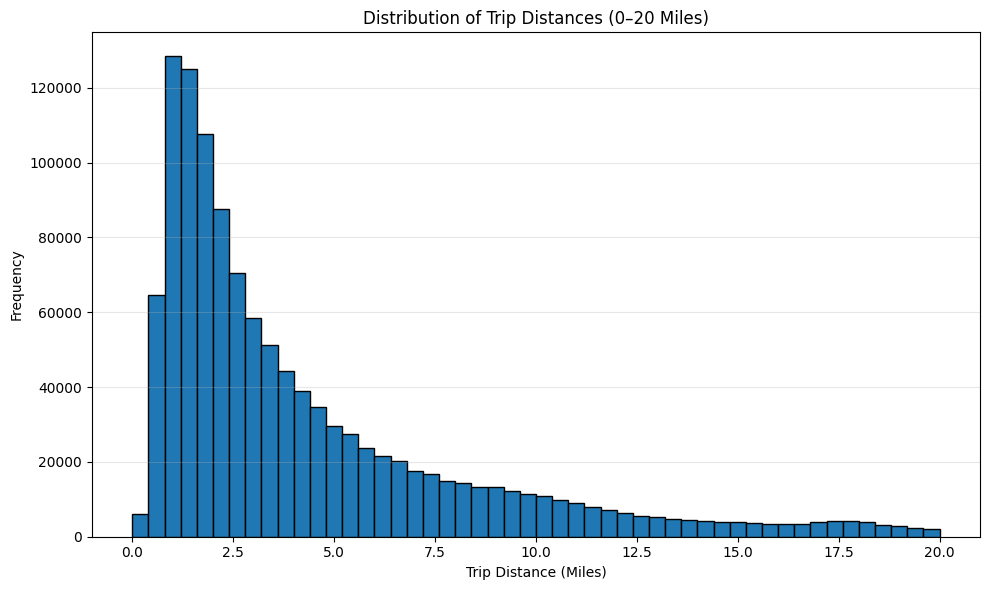

Histogram generated successfully!
Sample records used: 1177568


In [32]:
import matplotlib.pyplot as plt

# Prepare distance data using the existing Spark DataFrame
distance_pd = (
    df_distance
    .filter((df_distance["trip_miles"] > 0) & (df_distance["trip_miles"] <= 20))
    .select("trip_miles")
    .sample(False, 0.02, seed=42)
    .toPandas()
)

# Plot histogram
plt.figure(figsize=(10, 6))

plt.hist(
    distance_pd["trip_miles"],
    bins=50,
    range=(0, 20),
    edgecolor="black"
)

plt.title("Distribution of Trip Distances (0–20 Miles)")
plt.xlabel("Trip Distance (Miles)")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("Histogram generated successfully!")
print("Sample records used:", len(distance_pd))

Short trips dominate: Sample mein sabse zyada trips roughly 1 mile ke aas-paas concentrated hain.

Distance badhne par frequency kam hoti hai: 2–3 miles ke baad trips ki frequency generally decline karti hai.

Right-skewed distribution: Kuch long-distance trips ki wajah se distribution right side mein extend hota hai.

Longer trips bhi hain: 10–20 miles ke beech trips ki frequency comparatively kam hai.

### Trip Distance Distribution Analysis

The trip distance distribution shows that a large proportion of trips in the sampled dataset are concentrated within shorter travel distances. Trip frequency generally decreases as distance increases, resulting in a right-skewed distribution. The overall average trip distance was approximately 4.91 miles, while the median was 2.89 miles, suggesting that longer trips may be influencing the average. These findings can help identify common travel-distance patterns and support urban mobility demand analysis.

In [33]:
df_all.select(
    F.avg("trip_time").alias("average_duration_seconds"),
    F.min("trip_time").alias("minimum_duration_seconds"),
    F.max("trip_time").alias("maximum_duration_seconds"),
    F.expr("percentile_approx(trip_time, 0.5)").alias("median_duration_seconds")
).show()

+------------------------+------------------------+------------------------+-----------------------+
|average_duration_seconds|minimum_duration_seconds|maximum_duration_seconds|median_duration_seconds|
+------------------------+------------------------+------------------------+-----------------------+
|      1147.9116842359658|                       0|                   55138|                    938|
+------------------------+------------------------+------------------------+-----------------------+



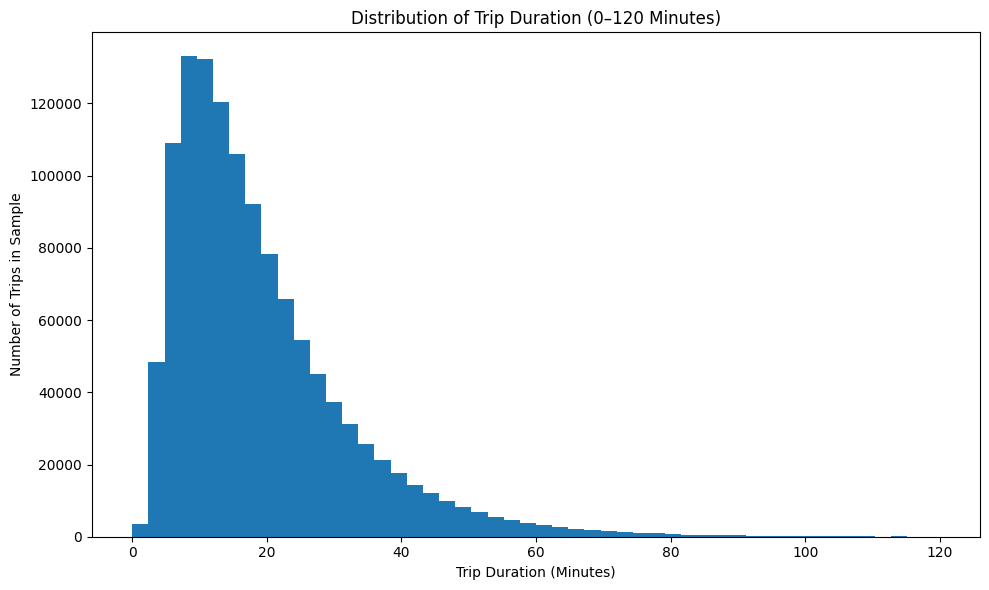

In [34]:
duration_pd = (
    df_all
    .filter(
        (F.col("trip_time") > 0) &
        (F.col("trip_time") <= 7200)
    )
    .select((F.col("trip_time") / 60).alias("duration_minutes"))
    .sample(False, 0.02, seed=42)
    .toPandas()
)

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(duration_pd["duration_minutes"], bins=50)

plt.title("Distribution of Trip Duration (0–120 Minutes)")
plt.xlabel("Trip Duration (Minutes)")
plt.ylabel("Number of Trips in Sample")

plt.tight_layout()
plt.show()

### Trip Duration Analysis

The trip duration distribution indicates that most sampled trips are relatively short, with a high concentration around 8–15 minutes. The frequency of trips generally decreases as duration increases, resulting in a right-skewed distribution. The overall average trip duration was approximately 19.13 minutes, compared with a median of 15.63 minutes. This difference suggests that longer-duration trips may influence the average. Understanding trip duration patterns can help characterize urban travel demand and identify unusually long trips for further investigation.

In [35]:
df_all.select(
    F.avg("base_passenger_fare").alias("average_base_fare"),
    F.min("base_passenger_fare").alias("minimum_base_fare"),
    F.max("base_passenger_fare").alias("maximum_base_fare"),
    F.expr(
        "percentile_approx(base_passenger_fare, 0.5)"
    ).alias("median_base_fare")
).show()

+------------------+-----------------+-----------------+----------------+
| average_base_fare|minimum_base_fare|maximum_base_fare|median_base_fare|
+------------------+-----------------+-----------------+----------------+
|24.619148414136543|           -140.7|          1911.16|           18.71|
+------------------+-----------------+-----------------+----------------+



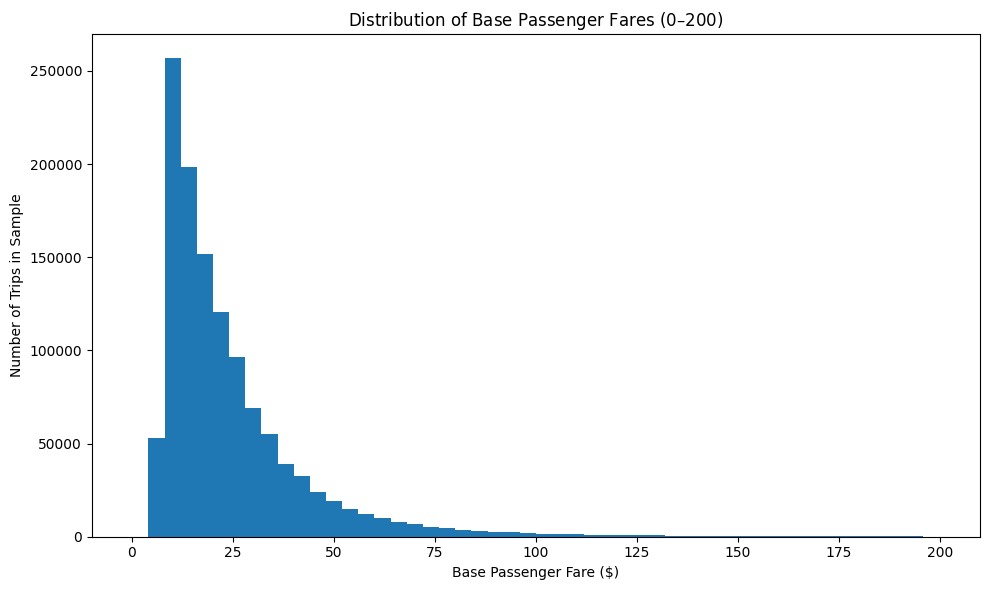

In [36]:
fare_pd = (
    df_all
    .filter(
        (F.col("base_passenger_fare") > 0) &
        (F.col("base_passenger_fare") <= 200)
    )
    .select("base_passenger_fare")
    .sample(False, 0.02, seed=42)
    .toPandas()
)

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(fare_pd["base_passenger_fare"], bins=50)

plt.title("Distribution of Base Passenger Fares ($0–$200)")
plt.xlabel("Base Passenger Fare ($)")
plt.ylabel("Number of Trips in Sample")

plt.tight_layout()
plt.show()

### Base Passenger Fare Analysis

The base passenger fare distribution shows that trips are concentrated in the lower fare ranges, with the highest frequency appearing around the $8–$15 range. The frequency of trips generally decreases as the fare increases, indicating a right-skewed distribution. The overall average base fare was approximately $24.62, while the median was $18.71. This difference suggests that higher-fare trips may influence the average. Negative and unusually high fare values should be investigated separately as part of data quality assessment.

In [37]:
df_all.groupBy("shared_request_flag").count().show()

df_all.groupBy("shared_match_flag").count().show()

+-------------------+--------+
|shared_request_flag|   count|
+-------------------+--------+
|                  Y| 2269145|
|                  N|58034721|
+-------------------+--------+

+-----------------+--------+
|shared_match_flag|   count|
+-----------------+--------+
|                Y|  769334|
|                N|59534532|
+-----------------+--------+



In [38]:
total_trips = df_all.count()

shared_requests = 2269145
shared_matches = 769334

print("Total trips:", f"{total_trips:,}")
print(
    "Shared ride requests:",
    f"{shared_requests / total_trips * 100:.2f}%"
)
print(
    "Shared ride matches:",
    f"{shared_matches / total_trips * 100:.2f}%"
)

Total trips: 60,303,866
Shared ride requests: 3.76%
Shared ride matches: 1.28%


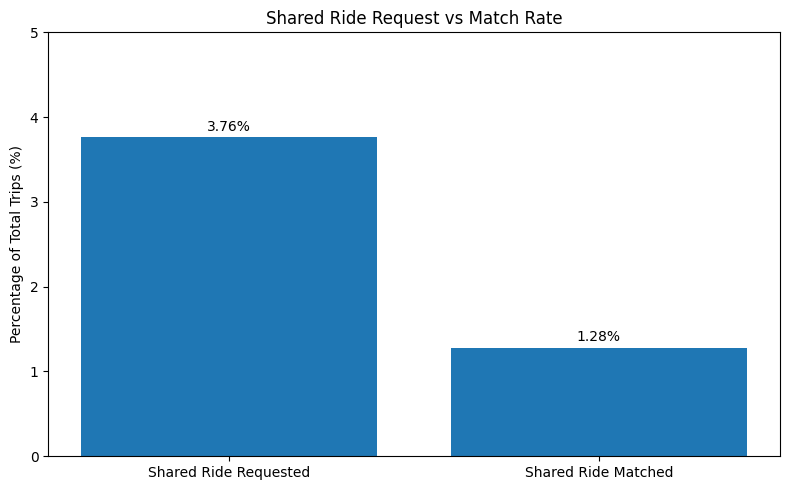

In [39]:
import matplotlib.pyplot as plt

categories = ["Shared Ride Requested", "Shared Ride Matched"]
percentages = [3.76, 1.28]

plt.figure(figsize=(8, 5))

bars = plt.bar(categories, percentages)

plt.title("Shared Ride Request vs Match Rate")
plt.ylabel("Percentage of Total Trips (%)")

plt.ylim(0, 5)

for bar in bars:
    value = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.08,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

### Shared Ride Analysis

Out of 60,303,866 trips recorded between January and March 2024, approximately 3.76% had a shared-ride request, while 1.28% had a successful shared-ride match. This indicates that shared-ride matches represented a relatively small proportion of all recorded trips during the study period. Further analysis of requested and matched shared rides could help identify opportunities to improve ride-sharing utilization and support sustainable urban mobility planning.


In [40]:
from pyspark.sql import functions as F

df_weekday = (
    df_all
    .withColumn(
        "day_of_week",
        F.date_format("pickup_datetime", "EEEE")
    )
    .groupBy("day_of_week")
    .agg(
        F.count("*").alias("total_pickups"),
        F.countDistinct(
            F.to_date("pickup_datetime")
        ).alias("number_of_days")
    )
    .withColumn(
        "average_daily_pickups",
        F.col("total_pickups") / F.col("number_of_days")
    )
)

# Days ko Monday se Sunday tak sort karna
day_order = F.when(F.col("day_of_week") == "Monday", 1) \
    .when(F.col("day_of_week") == "Tuesday", 2) \
    .when(F.col("day_of_week") == "Wednesday", 3) \
    .when(F.col("day_of_week") == "Thursday", 4) \
    .when(F.col("day_of_week") == "Friday", 5) \
    .when(F.col("day_of_week") == "Saturday", 6) \
    .when(F.col("day_of_week") == "Sunday", 7)

df_weekday = df_weekday.orderBy(day_order)

df_weekday.show(truncate=False)


+-----------+-------------+--------------+---------------------+
|day_of_week|total_pickups|number_of_days|average_daily_pickups|
+-----------+-------------+--------------+---------------------+
|Monday     |7431499      |13            |571653.7692307692    |
|Tuesday    |7628645      |13            |586818.8461538461    |
|Wednesday  |8209844      |13            |631526.4615384615    |
|Thursday   |8627592      |13            |663660.9230769231    |
|Friday     |9424809      |13            |724985.3076923077    |
|Saturday   |10331978     |13            |794767.5384615385    |
|Sunday     |8649499      |13            |665346.0769230769    |
+-----------+-------------+--------------+---------------------+



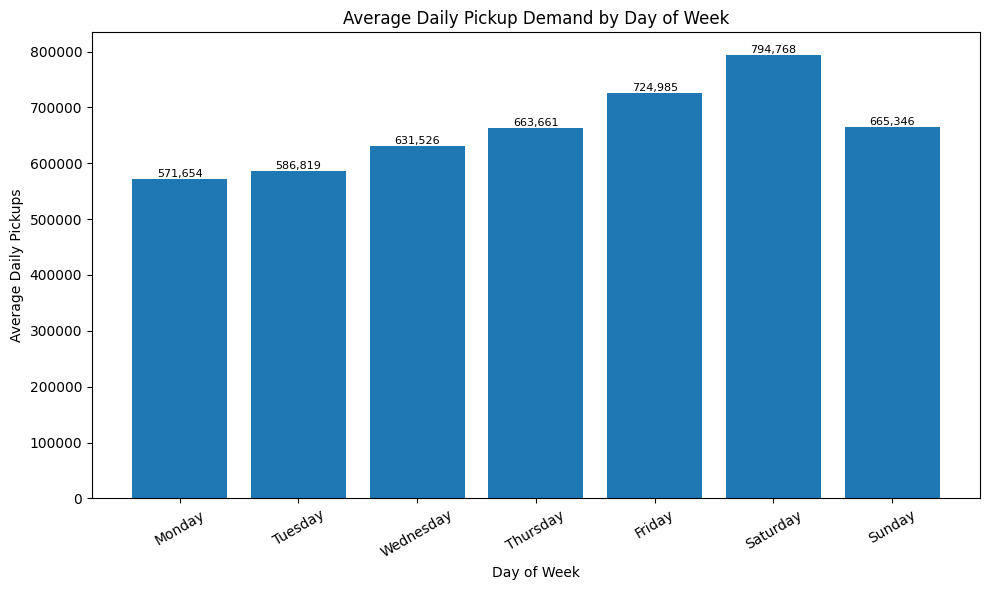

In [41]:
import matplotlib.pyplot as plt

weekday_pd = df_weekday.toPandas()

plt.figure(figsize=(10, 6))

bars = plt.bar(
    weekday_pd["day_of_week"],
    weekday_pd["average_daily_pickups"]
)

plt.title("Average Daily Pickup Demand by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Daily Pickups")
plt.xticks(rotation=30)

for bar in bars:
    value = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:,.0f}",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.tight_layout()
plt.show()

### Day-of-Week Demand Analysis

The analysis of NYC high-volume for-hire vehicle trips from January to March 2024 shows that Saturday recorded the highest average daily pickup demand, at approximately 794,768 trips. Monday recorded the lowest average, at approximately 571,654 trips. Average demand generally increased from Monday through Saturday before declining on Sunday. Saturday's average daily demand was approximately 39% higher than Monday's, highlighting substantial variation in travel demand across the week.

## ML PART

In [42]:
from pyspark.sql import functions as F

df_demand = (
    df_all
    .withColumn("pickup_date", F.to_date("pickup_datetime"))
    .groupBy("pickup_date")
    .agg(
        F.count("*").alias("total_pickups")
    )
    .orderBy("pickup_date")
)

df_demand.show(10, truncate=False)


+-----------+-------------+
|pickup_date|total_pickups|
+-----------+-------------+
|2024-01-01 |638406       |
|2024-01-02 |478254       |
|2024-01-03 |498332       |
|2024-01-04 |572632       |
|2024-01-05 |656654       |
|2024-01-06 |709028       |
|2024-01-07 |542767       |
|2024-01-08 |519594       |
|2024-01-09 |624357       |
|2024-01-10 |567258       |
+-----------+-------------+
only showing top 10 rows


In [43]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window

window_spec = Window.orderBy("pickup_date")

df_features = (
    df_demand
    .withColumn(
        "day_of_week",
        F.dayofweek("pickup_date")
    )
    .withColumn(
        "day_of_month",
        F.dayofmonth("pickup_date")
    )
    .withColumn(
        "previous_day_demand",
        F.lag("total_pickups", 1).over(window_spec)
    )
    .withColumn(
        "previous_7_day_demand",
        F.lag("total_pickups", 7).over(window_spec)
    )
)

df_features.show(10, truncate=False)

+-----------+-------------+-----------+------------+-------------------+---------------------+
|pickup_date|total_pickups|day_of_week|day_of_month|previous_day_demand|previous_7_day_demand|
+-----------+-------------+-----------+------------+-------------------+---------------------+
|2024-01-01 |638406       |2          |1           |NULL               |NULL                 |
|2024-01-02 |478254       |3          |2           |638406             |NULL                 |
|2024-01-03 |498332       |4          |3           |478254             |NULL                 |
|2024-01-04 |572632       |5          |4           |498332             |NULL                 |
|2024-01-05 |656654       |6          |5           |572632             |NULL                 |
|2024-01-06 |709028       |7          |6           |656654             |NULL                 |
|2024-01-07 |542767       |1          |7           |709028             |NULL                 |
|2024-01-08 |519594       |2          |8          

In [44]:
# Remove rows with missing lagged values
df_ml = df_features.dropna(
    subset=[
        "previous_day_demand",
        "previous_7_day_demand"
    ]
)

# Check dataset size
print("Total rows for ML:", df_ml.count())

# Split chronologically: first 80% for training, last 20% for testing
df_ml = df_ml.orderBy("pickup_date")

total_rows = df_ml.count()
split_point = int(total_rows * 0.8)

df_train = df_ml.limit(split_point)

df_test = (
    df_ml
    .orderBy(F.col("pickup_date").desc())
    .limit(total_rows - split_point)
    .orderBy("pickup_date")
)

print("Training rows:", df_train.count())
print("Testing rows:", df_test.count())

df_train.show(5, truncate=False)

Total rows for ML: 84
Training rows: 67
Testing rows: 17
+-----------+-------------+-----------+------------+-------------------+---------------------+
|pickup_date|total_pickups|day_of_week|day_of_month|previous_day_demand|previous_7_day_demand|
+-----------+-------------+-----------+------------+-------------------+---------------------+
|2024-01-08 |519594       |2          |8           |542767             |638406               |
|2024-01-09 |624357       |3          |9           |519594             |478254               |
|2024-01-10 |567258       |4          |10          |624357             |498332               |
|2024-01-11 |608276       |5          |11          |567258             |572632               |
|2024-01-12 |683589       |6          |12          |608276             |656654               |
+-----------+-------------+-----------+------------+-------------------+---------------------+
only showing top 5 rows


## TRAIN

In [45]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import RandomForestRegressor
from pyspark.ml import Pipeline
from pyspark.ml.evaluation import RegressionEvaluator

# Features used for prediction
feature_cols = [
    "day_of_week",
    "day_of_month",
    "previous_day_demand",
    "previous_7_day_demand"
]

# Create feature assembler
assembler = VectorAssembler(
    inputCols=feature_cols,
    outputCol="features"
)

# Create Random Forest model
rf = RandomForestRegressor(
    featuresCol="features",
    labelCol="total_pickups",
    numTrees=50,
    maxDepth=5,
    seed=42
)

# Create pipeline
pipeline = Pipeline(stages=[assembler, rf])

# Train the model
model = pipeline.fit(df_train)

print("Random Forest model trained successfully!")

# Check model predictions
predictions = model.transform(df_test)

predictions.select(
    "total_pickups",
    "prediction"
).show(10)

Random Forest model trained successfully!
+-------------+-----------------+
|total_pickups|       prediction|
+-------------+-----------------+
|       740231|732409.4042344879|
|       781234|820120.9966666667|
|       651847|676909.2386263736|
|       570102|587451.9600754768|
|       595922|595453.1667574842|
|       634866|626684.5804442866|
|       679116|670182.0777536831|
|       744124|728091.3475916306|
|       875253|798860.2226666666|
|       681416|683480.7341785713|
+-------------+-----------------+
only showing top 10 rows


In [46]:
# Generate predictions on test data
predictions = model.transform(df_test)

# Display actual vs predicted demand
predictions.select(
    "pickup_date",
    "total_pickups",
    "prediction"
).show(17, truncate=False)

+-----------+-------------+-----------------+
|pickup_date|total_pickups|prediction       |
+-----------+-------------+-----------------+
|2024-03-15 |740231       |732409.4042344879|
|2024-03-16 |781234       |820120.9966666667|
|2024-03-17 |651847       |676909.2386263736|
|2024-03-18 |570102       |587451.9600754768|
|2024-03-19 |595922       |595453.1667574842|
|2024-03-20 |634866       |626684.5804442866|
|2024-03-21 |679116       |670182.0777536831|
|2024-03-22 |744124       |728091.3475916306|
|2024-03-23 |875253       |798860.2226666666|
|2024-03-24 |681416       |683480.7341785713|
|2024-03-25 |569245       |574062.0542327411|
|2024-03-26 |592684       |586791.5456838292|
|2024-03-27 |641618       |632124.8972061913|
|2024-03-28 |711645       |671219.6504679689|
|2024-03-29 |718176       |741150.2284444445|
|2024-03-30 |749228       |799085.9083333334|
|2024-03-31 |658531       |690676.0778734827|
+-----------+-------------+-----------------+



In [47]:
from pyspark.ml.evaluation import RegressionEvaluator

# Mean Absolute Error
mae_evaluator = RegressionEvaluator(
    labelCol="total_pickups",
    predictionCol="prediction",
    metricName="mae"
)

# Root Mean Squared Error
rmse_evaluator = RegressionEvaluator(
    labelCol="total_pickups",
    predictionCol="prediction",
    metricName="rmse"
)

# R-squared
r2_evaluator = RegressionEvaluator(
    labelCol="total_pickups",
    predictionCol="prediction",
    metricName="r2"
)

mae = mae_evaluator.evaluate(predictions)
rmse = rmse_evaluator.evaluate(predictions)
r2 = r2_evaluator.evaluate(predictions)

print(f"MAE: {mae:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"R² Score: {r2:.4f}")

MAE: 21,576.49
RMSE: 29,281.43
R² Score: 0.8639


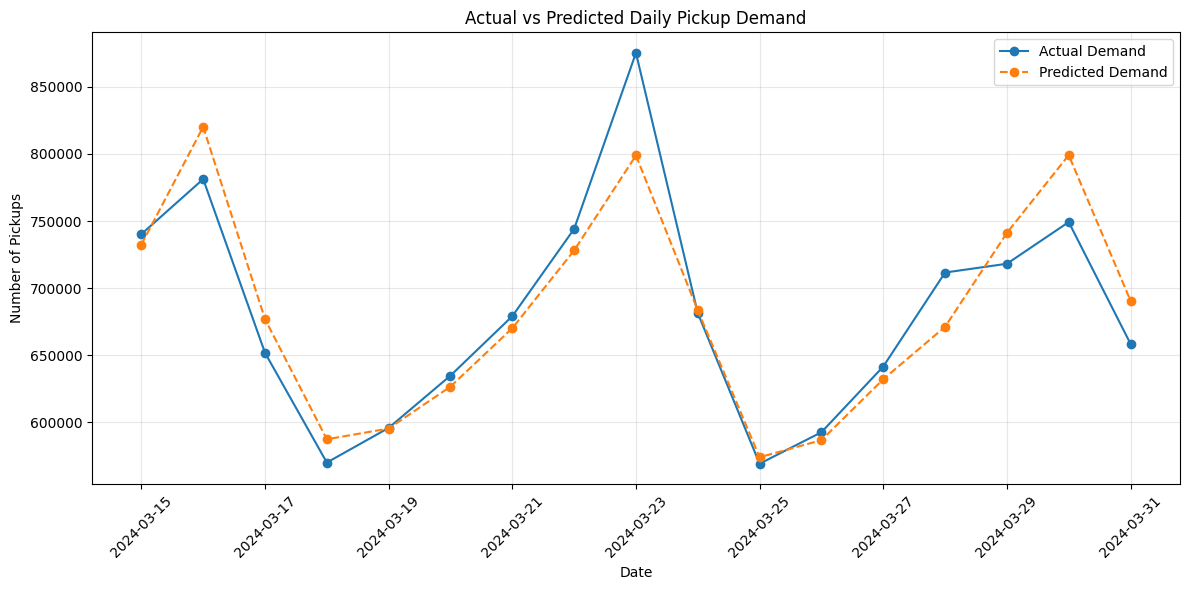

In [48]:
import matplotlib.pyplot as plt

comparison_pd = predictions.select(
    "pickup_date",
    "total_pickups",
    "prediction"
).orderBy("pickup_date").toPandas()

plt.figure(figsize=(12, 6))

plt.plot(
    comparison_pd["pickup_date"],
    comparison_pd["total_pickups"],
    marker="o",
    label="Actual Demand"
)

plt.plot(
    comparison_pd["pickup_date"],
    comparison_pd["prediction"],
    marker="o",
    linestyle="--",
    label="Predicted Demand"
)

plt.title("Actual vs Predicted Daily Pickup Demand")
plt.xlabel("Date")
plt.ylabel("Number of Pickups")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [49]:
from pyspark.ml.evaluation import RegressionEvaluator

baseline_predictions = predictions.withColumn(
    "baseline_prediction",
    F.col("previous_7_day_demand").cast("double")
)

mae_eval = RegressionEvaluator(
    labelCol="total_pickups",
    predictionCol="prediction",
    metricName="mae"
)

baseline_mae_eval = RegressionEvaluator(
    labelCol="total_pickups",
    predictionCol="baseline_prediction",
    metricName="mae"
)

rf_mae = mae_eval.evaluate(predictions)
baseline_mae = baseline_mae_eval.evaluate(baseline_predictions)

print(f"Random Forest MAE: {rf_mae:,.2f}")
print(f"7-day baseline MAE: {baseline_mae:,.2f}")

Random Forest MAE: 21,576.49
7-day baseline MAE: 31,450.47


### Demand Prediction Model Evaluation

A Random Forest Regression model was developed to predict daily pickup demand using day-of-week, day-of-month, previous-day demand, and previous-seven-day demand as input features. The model achieved an MAE of 21,576.49 pickups, an RMSE of 29,281.43 pickups, and an R² score of 0.8639 on the test set. A seven-day historical-demand baseline achieved an MAE of 31,450.47 pickups. Thus, the Random Forest model reduced MAE by approximately 31.3% compared with the baseline on the evaluated test period. However, the test set contained only 17 days, so further validation on a longer historical period is required to assess generalization.

## Final 7-Day Forecast

Run this cell after the model-training/loading cell. The forecast is based on the historical dataset end date.

In [50]:
from datetime import timedelta
import pandas as pd

# Build daily history from the existing Spark DataFrame.
daily_rows = (
    df_demand.orderBy("pickup_date")
    .select("pickup_date", "total_pickups")
    .collect()
)

history = [int(row["total_pickups"]) for row in daily_rows]
current_date = daily_rows[-1]["pickup_date"]
forecast_results = []

# Recursive 7-day forecast using the saved/trained pipeline model.
for _ in range(7):
    next_date = current_date + timedelta(days=1)
    # Spark dayofweek convention: Sunday=1 ... Saturday=7
    day_of_week = (next_date.isoweekday() % 7) + 1

    input_df = spark.createDataFrame(
        [(float(day_of_week), float(next_date.day),
          float(history[-1]), float(history[-7]))],
        ["day_of_week", "day_of_month", "previous_day_demand", "previous_7_day_demand"]
    )

    predicted = model.transform(input_df).select("prediction").first()[0]
    predicted = max(0, int(round(predicted)))

    forecast_results.append({
        "forecast_date": next_date.strftime("%Y-%m-%d"),
        "predicted_pickups": predicted
    })
    history.append(predicted)
    current_date = next_date

forecast_pd = pd.DataFrame(forecast_results)
print("7-Day Urban Mobility Demand Forecast")
print(forecast_pd.to_string(index=False))


7-Day Urban Mobility Demand Forecast
forecast_date  predicted_pickups
   2024-04-01             582822
   2024-04-02             591242
   2024-04-03             632999
   2024-04-04             667285
   2024-04-05             731217
   2024-04-06             785005
   2024-04-07             676950


## Historical Demand + Forecast Graph

This chart shows the final 14 historical days and the following 7 forecast days.

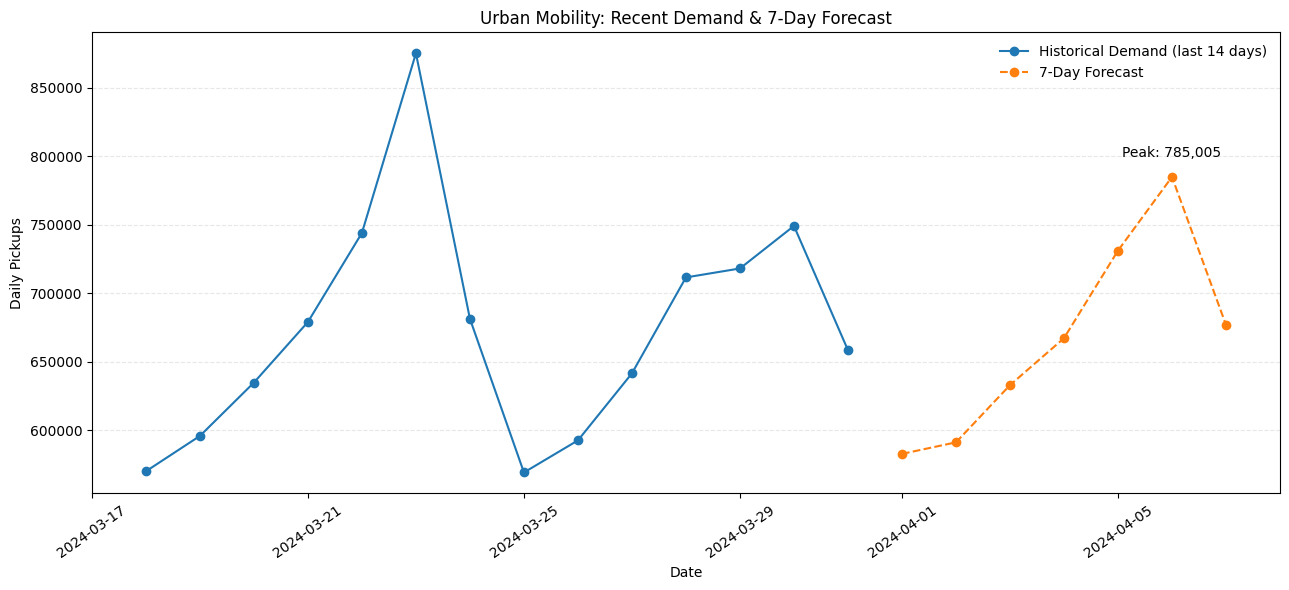

In [51]:
import matplotlib.pyplot as plt
import pandas as pd

# Show last 14 historical days plus the next 7 forecast days.
historical_pd = df_demand.select("pickup_date", "total_pickups").toPandas()
historical_pd = historical_pd.rename(columns={
    "pickup_date": "Date", "total_pickups": "Daily Pickups"
})
historical_pd["Date"] = pd.to_datetime(historical_pd["Date"])
historical_last14 = historical_pd.tail(14)

# Use forecast_results directly; avoid relying on stale DataFrame column names.
forecast_pd = pd.DataFrame(forecast_results)
forecast_pd["Date"] = pd.to_datetime(forecast_pd["forecast_date"])
forecast_pd["Daily Pickups"] = forecast_pd["predicted_pickups"]

fig, ax = plt.subplots(figsize=(13, 6))
ax.plot(historical_last14["Date"], historical_last14["Daily Pickups"],
        marker="o", label="Historical Demand (last 14 days)")
ax.plot(forecast_pd["Date"], forecast_pd["Daily Pickups"],
        marker="o", linestyle="--", label="7-Day Forecast")

peak = forecast_pd.loc[forecast_pd["Daily Pickups"].idxmax()]
ax.annotate(f"Peak: {int(peak['Daily Pickups']):,}",
            (peak["Date"], peak["Daily Pickups"]),
            xytext=(0, 14), textcoords="offset points", ha="center")
ax.set_title("Urban Mobility: Recent Demand & 7-Day Forecast")
ax.set_xlabel("Date")
ax.set_ylabel("Daily Pickups")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend(frameon=False)
ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()


In [52]:
print("Dataset folder:", folder)
print("Available columns:")
df_all.printSchema()

Dataset folder: C:\Users\aarus\Downloads\Big Data Dataset
Available columns:
root
 |-- hvfhs_license_num: string (nullable = true)
 |-- dispatching_base_num: string (nullable = true)
 |-- originating_base_num: string (nullable = true)
 |-- request_datetime: timestamp_ntz (nullable = true)
 |-- on_scene_datetime: timestamp_ntz (nullable = true)
 |-- pickup_datetime: timestamp_ntz (nullable = true)
 |-- dropoff_datetime: timestamp_ntz (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- trip_miles: double (nullable = true)
 |-- trip_time: long (nullable = true)
 |-- base_passenger_fare: double (nullable = true)
 |-- tolls: double (nullable = true)
 |-- bcf: double (nullable = true)
 |-- sales_tax: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- airport_fee: double (nullable = true)
 |-- tips: double (nullable = true)
 |-- driver_pay: double (nullable = true)
 |-- shared_request_flag: string (nul

In [53]:
import os

output_folder = os.path.join(folder, "powerbi_data")
os.makedirs(output_folder, exist_ok=True)

print("Power BI folder created:", output_folder)

Power BI folder created: C:\Users\aarus\Downloads\Big Data Dataset\powerbi_data


In [55]:
from pyspark.sql import functions as F

# Step 1: Check whether the original dataset is available
if "df_all" not in globals():
    raise NameError(
        "df_all is not defined. Run the cells that load and combine "
        "January, February and March datasets first."
    )

# Step 2: Verify required columns
required_columns = [
    "pickup_datetime",
    "PULocationID",
    "base_passenger_fare",
    "trip_miles"
]

missing_columns = [
    col for col in required_columns
    if col not in df_all.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

# Step 3: Create date-wise pickup location summary
df_location_by_date = (
    df_all
    .filter(
        F.col("pickup_datetime").isNotNull() &
        F.col("PULocationID").isNotNull()
    )
    .withColumn(
        "pickup_date",
        F.to_date("pickup_datetime")
    )
    .groupBy("pickup_date", "PULocationID")
    .agg(
        F.count("*").alias("total_pickups"),
        F.round(
            F.avg("base_passenger_fare"), 2
        ).alias("avg_base_fare"),
        F.round(
            F.avg("trip_miles"), 2
        ).alias("avg_trip_miles")
    )
    .orderBy("pickup_date", F.desc("total_pickups"))
)

# Step 4: Display results
print("Date-wise Pickup Location Summary created!")

df_location_by_date.show(10, truncate=False)

print("Total records:", df_location_by_date.count())

Date-wise Pickup Location Summary created!
+-----------+------------+-------------+-------------+--------------+
|pickup_date|PULocationID|total_pickups|avg_base_fare|avg_trip_miles|
+-----------+------------+-------------+-------------+--------------+
|2024-01-01 |132         |15049        |68.04        |19.05         |
|2024-01-01 |37          |11135        |29.15        |4.54          |
|2024-01-01 |138         |10437        |45.8         |11.12         |
|2024-01-01 |79          |9889         |32.62        |4.77          |
|2024-01-01 |61          |9491         |23.36        |4.13          |
|2024-01-01 |36          |8612         |29.95        |4.4           |
|2024-01-01 |80          |8298         |33.15        |4.97          |
|2024-01-01 |148         |8143         |37.96        |5.2           |
|2024-01-01 |7           |7755         |24.89        |5.58          |
|2024-01-01 |255         |7638         |35.87        |4.95          |
+-----------+------------+-------------+-------

In [56]:
import os

# Export folder
output_folder = r"C:\Users\aarus\Downloads\Big Data Dataset"

# Convert Spark DataFrame to Pandas
location_date_pd = df_location_by_date.toPandas()

# CSV file path
csv_path = os.path.join(
    output_folder,
    "pickup_location_by_date.csv"
)

# Export CSV
location_date_pd.to_csv(csv_path, index=False)

print("CSV exported successfully!")
print("File location:", csv_path)
print("Total records:", len(location_date_pd))

CSV exported successfully!
File location: C:\Users\aarus\Downloads\Big Data Dataset\pickup_location_by_date.csv
Total records: 23511


In [62]:
import os

# Convert existing daily demand summary to Pandas
daily_summary_pd = df_demand.toPandas()

# Export CSV
csv_path = os.path.join(output_folder, "daily_summary.csv")

daily_summary_pd.to_csv(csv_path, index=False)

print("Daily summary exported successfully!")
print("File saved at:", csv_path)
print("Total daily records:", len(daily_summary_pd))

Daily summary exported successfully!
File saved at: C:\Users\aarus\Downloads\Big Data Dataset\daily_summary.csv
Total daily records: 91


In [58]:
from pyspark.sql import functions as F
import os

# Hourly transportation demand summary
hourly_summary = (
    df_all
    .withColumn("pickup_date", F.to_date("pickup_datetime"))
    .withColumn("pickup_hour", F.hour("pickup_datetime"))
    .groupBy("pickup_date", "pickup_hour")
    .agg(
        F.count("*").alias("total_pickups")
    )
    .orderBy("pickup_date", "pickup_hour")
)

# Convert the aggregated data to Pandas
hourly_summary_pd = hourly_summary.toPandas()

# Export to CSV
hourly_csv_path = os.path.join(
    output_folder, "hourly_summary.csv"
)

hourly_summary_pd.to_csv(hourly_csv_path, index=False)

print("Hourly summary exported successfully!")
print("File saved at:", hourly_csv_path)
print("Total records:", len(hourly_summary_pd))

Hourly summary exported successfully!
File saved at: C:\Users\aarus\Downloads\Big Data Dataset\hourly_summary.csv
Total records: 2184


In [59]:
from pyspark.sql import functions as F
import os

# Top pickup locations
pickup_location_summary = (
    df_all
    .groupBy("PULocationID")
    .agg(
        F.count("*").alias("total_pickups"),
        F.round(F.avg("trip_miles"), 2).alias("avg_trip_miles"),
        F.round(F.avg("base_passenger_fare"), 2).alias("avg_base_fare")
    )
    .orderBy(F.desc("total_pickups"))
)

# Keep the top 50 locations for the dashboard
top_pickup_locations = pickup_location_summary.limit(50)

# Convert the small summary to Pandas
pickup_locations_pd = top_pickup_locations.toPandas()

# Save as CSV
pickup_csv_path = os.path.join(
    output_folder, "pickup_location_summary.csv"
)

pickup_locations_pd.to_csv(pickup_csv_path, index=False)

print("Pickup location summary exported successfully!")
print("File saved at:", pickup_csv_path)
print("Number of locations:", len(pickup_locations_pd))

Pickup location summary exported successfully!
File saved at: C:\Users\aarus\Downloads\Big Data Dataset\pickup_location_summary.csv
Number of locations: 50


In [60]:
import os
import pandas as pd

# Get the latest date and demand from historical data
last_row = df_demand.orderBy("pickup_date", ascending=False).first()

last_date = last_row["pickup_date"]

# Collect the latest 7 daily demand values
recent_rows = (
    df_demand
    .orderBy("pickup_date", ascending=False)
    .limit(7)
    .collect()
)

recent_demands = [
    float(row["total_pickups"])
    for row in reversed(recent_rows)
]

# Store forecast results
forecast_rows = []

# Generate predictions for the next 7 days
for i in range(1, 8):

    # Calculate forecast date
    forecast_date = last_date + pd.Timedelta(days=i)
    forecast_date = pd.Timestamp(forecast_date)

    # Calculate model features
    previous_day_demand = recent_demands[-1]
    previous_7_day_demand = sum(recent_demands[-7:]) / 7

    # Create input DataFrame for prediction
    input_df = spark.createDataFrame([{
        "day_of_week": int(forecast_date.dayofweek),
        "day_of_month": int(forecast_date.day),
        "previous_day_demand": float(previous_day_demand),
        "previous_7_day_demand": float(previous_7_day_demand)
    }])

    # Predict transportation demand
    prediction = model.transform(input_df) \
        .select("prediction") \
        .first()[0]

    prediction = max(0, float(prediction))

    # Save forecast result
    forecast_rows.append({
        "forecast_date": forecast_date.strftime("%Y-%m-%d"),
        "predicted_pickups": round(prediction)
    })

    # Use predicted demand for the next day's forecast
    recent_demands.append(prediction)

# Convert forecast results into Pandas DataFrame
forecast_pd = pd.DataFrame(forecast_rows)

# Save CSV file locally
forecast_path = os.path.join(
    output_folder,
    "demand_forecast.csv"
)

forecast_pd.to_csv(forecast_path, index=False)

# Display results
print("Forecast exported successfully!")
print("File saved at:", forecast_path)

display(forecast_pd)

Forecast exported successfully!
File saved at: C:\Users\aarus\Downloads\Big Data Dataset\demand_forecast.csv


,forecast_date,predicted_pickups
0,2024-04-01,658754
1,2024-04-02,660699
2,2024-04-03,659866
3,2024-04-04,668209
4,2024-04-05,674282
5,2024-04-06,675027
6,2024-04-07,722719


In [61]:
# Check columns available in the original dataset
df_all.printSchema()

print("Total columns:", len(df_all.columns))
print("Available columns:", df_all.columns)

root
 |-- hvfhs_license_num: string (nullable = true)
 |-- dispatching_base_num: string (nullable = true)
 |-- originating_base_num: string (nullable = true)
 |-- request_datetime: timestamp_ntz (nullable = true)
 |-- on_scene_datetime: timestamp_ntz (nullable = true)
 |-- pickup_datetime: timestamp_ntz (nullable = true)
 |-- dropoff_datetime: timestamp_ntz (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- trip_miles: double (nullable = true)
 |-- trip_time: long (nullable = true)
 |-- base_passenger_fare: double (nullable = true)
 |-- tolls: double (nullable = true)
 |-- bcf: double (nullable = true)
 |-- sales_tax: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- airport_fee: double (nullable = true)
 |-- tips: double (nullable = true)
 |-- driver_pay: double (nullable = true)
 |-- shared_request_flag: string (nullable = true)
 |-- shared_match_flag: string (nullable = true)
 |-- access_a_